# RetailPulse - Step 4: Churn Prediction

Predict which customers will cut their spending next quarter, check the accuracy honestly, see what drives it, and score today's customers.

Nobody in this data stops buying, so churn here means a **drop in spend**:

> churn = 1 if next quarter's spend at list price is more than 30% below the same quarter last year.

Comparing with the same quarter last year removes seasonality. To avoid leakage, features only use sales before each
cutoff and the label comes from the 3 months after it; models are tested on later quarters they haven't seen. Code: `src/churn.py`.

## 0. Setup

In [1]:
import sys, time
from pathlib import Path
import numpy as np, pandas as pd, joblib, shap
import matplotlib.pyplot as plt, seaborn as sns
from IPython.display import display
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (roc_auc_score, average_precision_score, brier_score_loss, roc_curve,
                             confusion_matrix, precision_score, recall_score)
from xgboost import XGBClassifier

ROOT = Path('..')
sys.path.append(str(ROOT))
from src.cleaning import connect
from src.churn import churn_table, CHURN_FEATURES, DROP_RATIO

PROC, MODELS = ROOT / 'data' / 'processed', ROOT / 'models'
FIG = ROOT / 'reports' / 'figures'; FIG.mkdir(parents=True, exist_ok=True)
pd.set_option('display.float_format', '{:,.3f}'.format); pd.set_option('display.width', 160)
sns.set_theme(style='whitegrid', palette='deep')
plt.rcParams.update({'figure.figsize': (11, 4.5), 'figure.dpi': 110, 'axes.titleweight': 'bold'})
def save(name): plt.savefig(FIG / f'{name}.png', bbox_inches='tight')
FLOAT = '%.4f'

con = connect(ROOT / 'retail_clean_dataset', PROC / 'sales_clean.parquet')

## 1. Building the churn dataset
One cutoff per quarter from Jan 2023 (a year of history is needed) to Oct 2025 (the last quarter with a known outcome): 12 cutoffs x 10,000 customers.

In [2]:
cutoffs = pd.date_range('2023-01-01', '2025-10-01', freq='QS')
t = time.time()
data = pd.concat([churn_table(con, c) for c in cutoffs])
print(f'{len(data):,} rows from {len(cutoffs)} cutoffs in {time.time() - t:.0f}s')

120,000 rows from 12 cutoffs in 88s


Why list price? A first version used spend after discounts, and its churn rate swung from 7% to 29% with the promo calendar:
customers "churned" just because the next quarter had bigger discounts. Using quantity x price removes that.

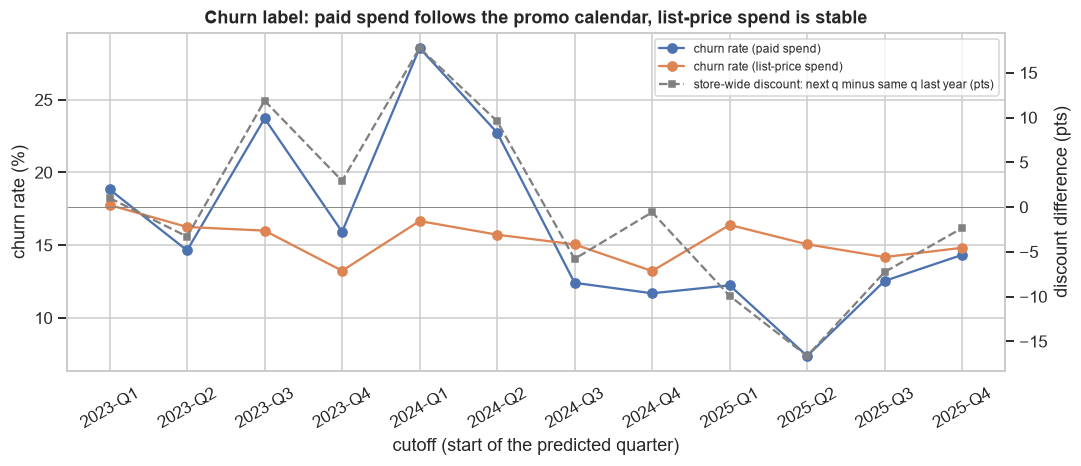

,churn rate (paid spend),churn rate (list-price spend),store-wide discount next q (%),store-wide discount same q last year (%)
cutoff,,,,
2023-01-01,0.188,0.178,1.011,0.000
2023-04-01,0.146,0.163,7.048,10.347
2023-07-01,0.237,0.160,13.049,1.174
2023-10-01,0.159,0.132,2.925,0.000
2024-01-01,0.286,0.167,18.777,1.011
2024-04-01,0.227,0.157,16.631,7.048
2024-07-01,0.124,0.150,7.261,13.049
2024-10-01,0.117,0.132,2.348,2.925
2025-01-01,0.122,0.164,8.860,18.777


In [3]:
def paid_spend(start, end):
    return con.sql(f"""SELECT customer_id, SUM(total_value) s FROM sales
                        WHERE date >= DATE '{start:%Y-%m-%d}' AND date < DATE '{end:%Y-%m-%d}' GROUP BY 1""").df().set_index('customer_id')['s']
q = pd.DateOffset(months=3)
promos = con.sql("SELECT start_date, end_date, discount_pct FROM promos WHERE target_type = 'All'").df()
def store_wide_discount(start, end):     # average store-wide discount % over the period
    days = pd.Series(0.0, index=pd.date_range(start, end - pd.Timedelta(days=1)))
    for r in promos.itertuples():
        days.loc[r.start_date:r.end_date] = np.maximum(days.loc[r.start_date:r.end_date], r.discount_pct)
    return days.mean()

rows = []
for c in cutoffs:
    nxt, ly = paid_spend(c, c + q), paid_spend(c - 4 * q, c - 3 * q)
    rows.append({'cutoff': c, 'churn rate (paid spend)': (nxt.reindex(ly.index).fillna(0) < DROP_RATIO * ly).mean(),
                 'churn rate (list-price spend)': data.loc[data['cutoff'] == c, 'churn'].mean(),
                 'store-wide discount next q (%)': store_wide_discount(c, c + q),
                 'store-wide discount same q last year (%)': store_wide_discount(c - 4 * q, c - 3 * q)})
labels = pd.DataFrame(rows).set_index('cutoff')

fig, ax = plt.subplots(figsize=(11, 4))
x = np.arange(len(labels))
for col in labels.columns[:2]: ax.plot(x, labels[col] * 100, marker='o', label=col)
ax2 = ax.twinx(); ax2.plot(x, labels.iloc[:, 2] - labels.iloc[:, 3], color='grey', ls='--', marker='s', ms=4,
                           label='store-wide discount: next q minus same q last year (pts)')
ax2.axhline(0, color='grey', lw=.6); ax2.grid(False); ax2.set_ylabel('discount difference (pts)')
ax.set_xticks(x, [f'{c:%Y}-Q{c.quarter}' for c in labels.index], rotation=30)
ax.set_ylabel('churn rate (%)'); ax.set_xlabel('cutoff (start of the predicted quarter)'); ax.set_title('Churn label: paid spend follows the promo calendar, list-price spend is stable')
h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels(); ax.legend(h1 + h2, l1 + l2, loc='upper right', fontsize=8)
save('04a_churn_label'); plt.show()
labels

- With paid spend the churn rate follows the discount gap (peak in Q1 2024, dip in Q2 2025), so a model would just learn the promo calendar.
- With list-price spend it's a steady 13-18% every quarter. That's the label used from here on.
- About 1 in 7 customers cuts spend by more than 30% in a given quarter.

## 2. Time-based split
| Split | Cutoffs | Outcome quarters | Used for |
|---|---|---|---|
| Train | Jan 2023 - Jan 2025 (9) | up to Mar 2025 | fitting |
| Validation | Apr 2025 | Apr-Jun 2025 | model choice, threshold |
| Test | Oct 2025 | Oct-Dec 2025 | final score, used once |

No training outcome overlaps validation, and no validation outcome overlaps test. The Jul 2025 cutoff is only used for the final refit.

In [4]:
train = data[data['cutoff'] <= '2025-01-01']
val   = data[data['cutoff'] == '2025-04-01']
test  = data[data['cutoff'] == '2025-10-01']
X = lambda d: d[CHURN_FEATURES]
pd.DataFrame({'rows': [len(train), len(val), len(test)],
              'churn rate': [train['churn'].mean(), val['churn'].mean(), test['churn'].mean()]},
             index=['train', 'validation', 'test'])

,rows,churn rate
train,90000,0.156
validation,10000,0.151
test,10000,0.148


## 3. Three models compared on validation
ROC-AUC (ranking), PR-AUC (better when churners are a minority), top-20% capture (share of churners found by contacting the riskiest 20%) and Brier score (probability accuracy, lower is better).

In [5]:
def top_capture(y, p, share=.2):
    top = np.argsort(-p)[:int(len(p) * share)]
    return y.to_numpy()[top].sum() / y.sum()

def evaluate(y, p):
    return {'ROC-AUC': roc_auc_score(y, p), 'PR-AUC': average_precision_score(y, p),
            'top-20% capture': top_capture(y, p), 'Brier': brier_score_loss(y, p),
            'predicted rate': p.mean(), 'actual rate': y.mean()}

models = {
    'LogReg': make_pipeline(SimpleImputer(strategy='median'), StandardScaler(), LogisticRegression(max_iter=2000)),
    'RandomForest': make_pipeline(SimpleImputer(strategy='median'),
                                  RandomForestClassifier(n_estimators=300, min_samples_leaf=20, n_jobs=-1, random_state=42)),
    'XGBoost': XGBClassifier(n_estimators=300, max_depth=4, learning_rate=0.05, subsample=0.8, colsample_bytree=0.8,
                             eval_metric='logloss', random_state=42),
}
val_scores = {}
for name, m in models.items():
    t = time.time(); m.fit(X(train), train['churn'])
    val_scores[name] = evaluate(val['churn'], m.predict_proba(X(val))[:, 1]) | {'fit_s': time.time() - t}
val_table = pd.DataFrame(val_scores).T
best_name = val_table['PR-AUC'].idxmax()
print('best on validation (PR-AUC):', best_name)
val_table

best on validation (PR-AUC): XGBoost


,ROC-AUC,PR-AUC,top-20% capture,Brier,predicted rate,actual rate,fit_s
LogReg,0.817,0.468,0.555,0.103,0.175,0.151,0.577
RandomForest,0.823,0.459,0.558,0.103,0.180,0.151,14.967
XGBoost,0.826,0.484,0.560,0.102,0.186,0.151,1.245


## 4. Final test
The threshold is set on validation (flag the riskiest 20%) and the same cut-off is applied to the test quarter.

In [6]:
test_scores = {name: evaluate(test['churn'], m.predict_proba(X(test))[:, 1]) for name, m in models.items()}
display(pd.DataFrame(test_scores).T)

best = models[best_name]
p_val, p_test = best.predict_proba(X(val))[:, 1], best.predict_proba(X(test))[:, 1]
threshold = np.quantile(p_val, 0.8)
flag = (p_test >= threshold).astype(int)
cm = pd.DataFrame(confusion_matrix(test['churn'], flag), index=['actual: stayed', 'actual: churned'],
                  columns=['predicted: stay', 'predicted: churn'])
display(cm)
print(f'{best_name} at threshold {threshold:.3f}: flags {flag.mean():.0%} of customers | '
      f'precision {precision_score(test["churn"], flag):.2f} | recall {recall_score(test["churn"], flag):.2f} | '
      f'base churn rate {test["churn"].mean():.2f}')

,ROC-AUC,PR-AUC,top-20% capture,Brier,predicted rate,actual rate
LogReg,0.826,0.441,0.572,0.105,0.192,0.148
RandomForest,0.839,0.493,0.598,0.103,0.214,0.148
XGBoost,0.844,0.518,0.604,0.096,0.174,0.148


,predicted: stay,predicted: churn
actual: stayed,7605,913
actual: churned,660,822


XGBoost at threshold 0.327: flags 17% of customers | precision 0.47 | recall 0.55 | base churn rate 0.15


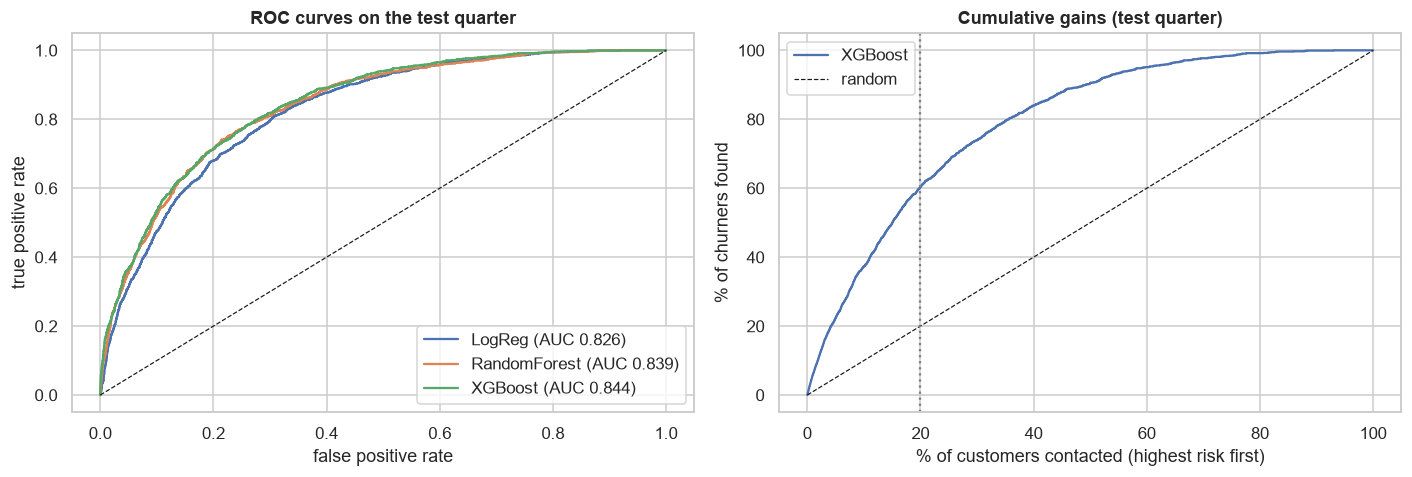

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
for name, m in models.items():
    p = m.predict_proba(X(test))[:, 1]; fpr, tpr, _ = roc_curve(test['churn'], p)
    ax[0].plot(fpr, tpr, label=f"{name} (AUC {roc_auc_score(test['churn'], p):.3f})")
ax[0].plot([0, 1], [0, 1], 'k--', lw=.8); ax[0].set_xlabel('false positive rate'); ax[0].set_ylabel('true positive rate')
ax[0].set_title('ROC curves on the test quarter'); ax[0].legend()

order = np.argsort(-p_test); y_sorted = test['churn'].to_numpy()[order]
share = np.arange(1, len(order) + 1) / len(order)
ax[1].plot(share * 100, np.cumsum(y_sorted) / y_sorted.sum() * 100, label=best_name)
ax[1].plot([0, 100], [0, 100], 'k--', lw=.8, label='random')
ax[1].axvline(20, color='grey', ls=':'); ax[1].set_xlabel('% of customers contacted (highest risk first)')
ax[1].set_ylabel('% of churners found'); ax[1].set_title('Cumulative gains (test quarter)'); ax[1].legend()
plt.tight_layout(); save('04b_roc_gains'); plt.show()

- XGBoost is best on both validation and test (test ROC-AUC **0.844**, PR-AUC 0.52). Random forest is close and even logistic regression gets 0.83, so the signal is fairly simple.
- Contacting the riskiest 20% finds **60% of churners**, 3x better than random.
- At the validation threshold the model flags 17% of customers; 47% of those really churn (vs 15% overall) and it finds 55% of all churners.
- Predicted churn on test (17%) is close to the actual 15%.

Is one test quarter enough? The same out-of-time test repeated for five quarters, each trained only on earlier outcomes.

In [8]:
rolling = []
for c in pd.date_range('2024-10-01', '2025-10-01', freq='QS'):
    tr = data[data['cutoff'] <= c - pd.DateOffset(months=6)]
    te = data[data['cutoff'] == c]
    m = XGBClassifier(**models['XGBoost'].get_params()).fit(X(tr), tr['churn'])
    rolling.append({'test quarter': f'{c:%Y-%m}', 'train cutoffs': tr['cutoff'].nunique()} | evaluate(te['churn'], m.predict_proba(X(te))[:, 1]))
pd.DataFrame(rolling).set_index('test quarter')

,train cutoffs,ROC-AUC,PR-AUC,top-20% capture,Brier,predicted rate,actual rate
test quarter,,,,,,,
2024-10,6,0.848,0.484,0.604,0.089,0.154,0.132
2025-01,7,0.829,0.508,0.558,0.107,0.182,0.164
2025-04,8,0.826,0.483,0.561,0.102,0.184,0.151
2025-07,9,0.835,0.472,0.579,0.099,0.188,0.142
2025-10,10,0.844,0.516,0.596,0.096,0.173,0.148


ROC-AUC stays between 0.83 and 0.85 and top-20% capture between 56% and 60%, so it wasn't a lucky quarter.
Predicted rates are within 2-4 points of actual, mostly thanks to `target_quarter` (without it Q4 churn was over-predicted about 2x).

## 5. What drives churn (SHAP)

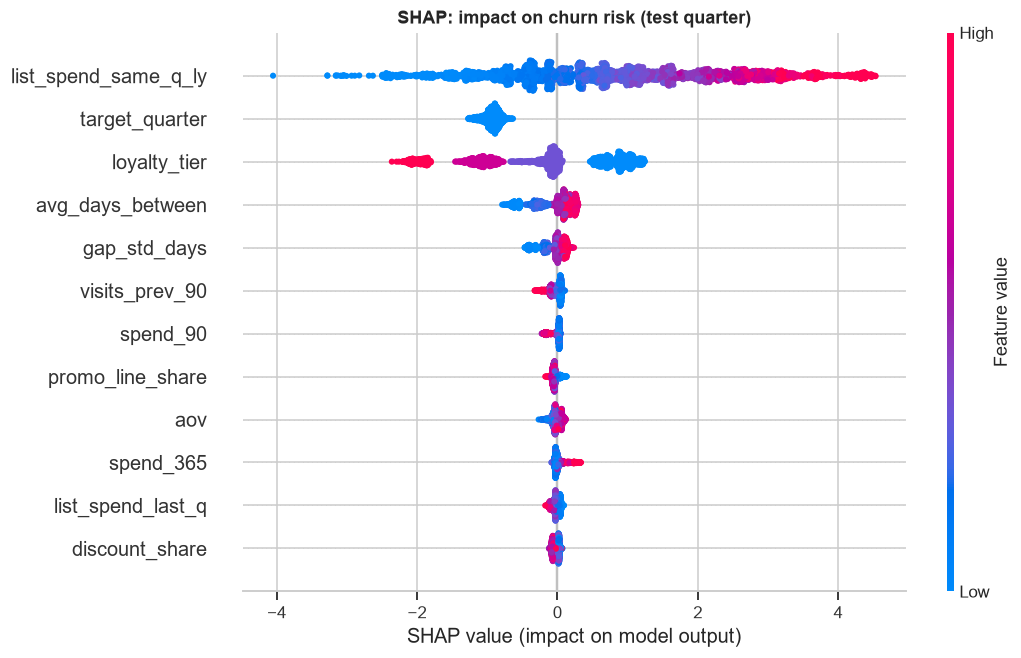

,mean |SHAP|
list_spend_same_q_ly,1.425
target_quarter,0.924
loyalty_tier,0.785
avg_days_between,0.212
gap_std_days,0.114
visits_prev_90,0.067
spend_90,0.054
promo_line_share,0.046
aov,0.046
spend_365,0.044


In [9]:
xgb = models['XGBoost']
sample = X(test).sample(3000, random_state=42)
sv = shap.TreeExplainer(xgb).shap_values(sample)
import warnings
warnings.filterwarnings('ignore', message='The NumPy global RNG was seeded')
np.random.seed(42)   # the dot layout uses random jitter
shap.summary_plot(sv, sample, max_display=12, show=False, plot_size=(10, 6))
plt.title('SHAP: impact on churn risk (test quarter)'); save('04c_churn_shap'); plt.show()
importance = pd.Series(np.abs(sv).mean(axis=0), index=sample.columns).sort_values(ascending=False)
importance.head(10).to_frame('mean |SHAP|')

In [10]:
# churn rate by the two strongest drivers (test quarter)
t2 = test.assign(ly_quarter_band=pd.qcut(test['list_spend_same_q_ly'] / (test['spend_365'] / 4), 4,
                                         labels=['low', 'mid-low', 'mid-high', 'high']))
display(t2.groupby('loyalty_segment')['churn'].mean().loc[['Bronze', 'Silver', 'Gold', 'Platinum']].to_frame('churn rate'))
t2.groupby('ly_quarter_band', observed=True)['churn'].mean().to_frame('churn rate by last-year quarter vs own average')

,churn rate
loyalty_segment,
Bronze,0.197
Silver,0.154
Gold,0.092
Platinum,0.046


,churn rate by last-year quarter vs own average
ly_quarter_band,
low,0.028
mid-low,0.070
mid-high,0.156
high,0.339


1. A strong quarter last year makes a drop more likely: 34% churn when that quarter was high vs the customer's average, 3% when it was low. A lot of this "churn" is just a return to normal.
2. Lower tiers churn more (Bronze 20% vs Platinum 5%); fewer visits means bumpier quarterly spend.
3. `target_quarter` shifts the baseline by season but doesn't change the ranking within a quarter.
4. Recency barely matters: a recent gap in visits doesn't predict a drop in spend here.

## 6. Scoring today's customers
The final model is refit on all cutoffs with a known outcome and applied to features at 1 Jan 2026 (predicting Q1 2026).

In [11]:
final = XGBClassifier(**models['XGBoost'].get_params()).fit(X(data), data['churn'])
now = pd.Timestamp('2026-01-01')
today = churn_table(con, now, with_label=False)
today['churn_prob'] = final.predict_proba(X(today))[:, 1]
today['risk_band'] = pd.cut(today['churn_prob'], [0, 0.4, 0.7, 1.0], labels=['Low', 'Medium', 'High'], include_lowest=True)

seg = pd.read_csv(PROC / 'customer_segments.csv', index_col='customer_id')['Segment']
today = today.join(seg)
print(f"predicted churn rate for Q1 2026: {today['churn_prob'].mean():.1%}")
bands = today.groupby('risk_band', observed=True).agg(customers=('churn_prob', 'size'), avg_prob=('churn_prob', 'mean'),
                                                       last_year_spend=('spend_365', 'sum'))
bands['share_%'] = bands['customers'] / len(today) * 100
bands['share_of_revenue_%'] = bands['last_year_spend'] / today['spend_365'].sum() * 100
bands   # revenue at risk = last-year spend of the High (and Medium) band

predicted churn rate for Q1 2026: 20.4%


,customers,avg_prob,last_year_spend,share_%,share_of_revenue_%
risk_band,,,,,
Low,8294,0.133,"2,530,421,429.470",82.940,84.043
Medium,1463,0.514,"414,156,168.830",14.630,13.755
High,243,0.784,"66,304,709.190",2.430,2.202


,customers,avg_churn_prob,high_risk,medium_risk
Segment,,,,
Champions,1020,0.114,0,81
Loyal,1889,0.153,25,152
Regulars,2377,0.206,48,344
Occasional,2397,0.254,88,477
Slipping Away,2317,0.232,82,409


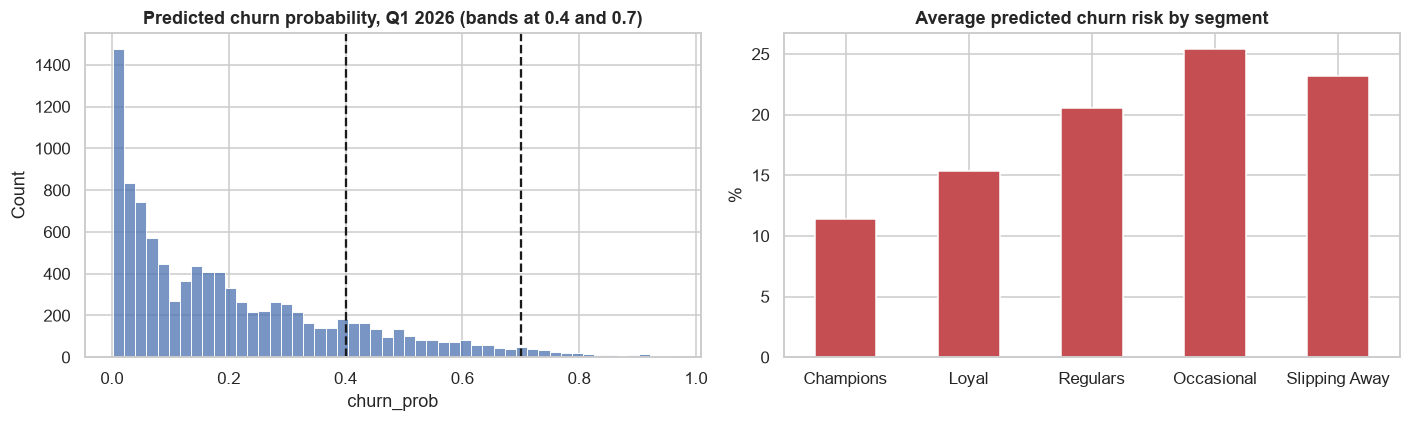

In [12]:
order = ['Champions', 'Loyal', 'Regulars', 'Occasional', 'Slipping Away']
by_seg = today.groupby('Segment').agg(customers=('churn_prob', 'size'), avg_churn_prob=('churn_prob', 'mean'),
                                      high_risk=('risk_band', lambda s: (s == 'High').sum()),
                                      medium_risk=('risk_band', lambda s: (s == 'Medium').sum())).loc[order]
display(by_seg)

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(today['churn_prob'], bins=50, ax=ax[0]); ax[0].axvline(.4, color='k', ls='--'); ax[0].axvline(.7, color='k', ls='--')
ax[0].set_title('Predicted churn probability, Q1 2026 (bands at 0.4 and 0.7)')
by_seg['avg_churn_prob'].mul(100).plot.bar(ax=ax[1], rot=0, color='C3'); ax[1].set_ylabel('%'); ax[1].set_xlabel('')
ax[1].set_title('Average predicted churn risk by segment')
plt.tight_layout(); save('04d_churn_today'); plt.show()

In [13]:
first_calls = today[(today['risk_band'] != 'Low') & (today['Segment'].isin(['Champions', 'Loyal']))] \
                .sort_values('churn_prob', ascending=False)
print(f'{len(first_calls)} medium/high-risk Champions or Loyal customers -- the first people to contact')
first_calls[['Segment', 'loyalty_segment', 'churn_prob', 'risk_band', 'spend_365']].head(10)

258 medium/high-risk Champions or Loyal customers -- the first people to contact


,Segment,loyalty_segment,churn_prob,risk_band,spend_365
customer_id,,,,,
CUST05928,Loyal,Gold,0.905,High,"453,764.430"
CUST04154,Loyal,Gold,0.904,High,"503,276.610"
CUST02783,Loyal,Gold,0.881,High,"538,539.790"
CUST09234,Loyal,Gold,0.850,High,"503,395.750"
CUST01312,Loyal,Gold,0.800,High,"483,277.830"
CUST09447,Loyal,Gold,0.755,High,"517,587.890"
CUST06644,Loyal,Gold,0.748,High,"502,925.550"
CUST03300,Loyal,Gold,0.743,High,"567,000.340"
CUST01667,Loyal,Gold,0.740,High,"503,976.500"


In [14]:
out = today[['churn_prob', 'risk_band', 'Segment', 'loyalty_segment', 'spend_365', 'recency_days', 'avg_days_between']]
out.to_csv(PROC / 'customer_churn.csv', index_label='customer_id', float_format=FLOAT)
joblib.dump({'model': final, 'features': CHURN_FEATURES, 'drop_ratio': DROP_RATIO, 'threshold_top20': threshold},
            MODELS / 'churn_xgb.pkl')
print('saved customer_churn.csv', out.shape, 'and models/churn_xgb.pkl')

saved customer_churn.csv (10000, 7) and models/churn_xgb.pkl


- **243 customers (2.4%) are high risk** (> 0.7) and 1,463 (14.6%) medium. They account for ~2% and ~14% of last year's revenue.
- The predicted Q1 2026 rate is 20%, a bit above past Q1s (16-18%), so treat the bands as a ranking rather than a firm forecast.
- Risk is highest for Occasional (25%) and Slipping Away (23%) and lowest for Champions (11%). Slipping Away isn't riskier than Occasional, which answers the question left open in Step 3.
- First calls: 258 medium/high-risk Champions or Loyal customers (mostly Gold, ~PKR 0.5M a year each).

## 7. MLflow tracking
Each model is logged to the `retailpulse-churn` experiment and the final model is registered as `churn_xgb`.
View with `mlflow ui --backend-store-uri sqlite:///mlflow.db` from the project root.

In [15]:
from src.tracking import use_experiment
mlflow = use_experiment('retailpulse-churn')
clean = lambda k: k.replace('-', '_').replace('%', 'pct').replace(' ', '_')
for name, m in models.items():
    with mlflow.start_run(run_name=f'{name.lower()}_baseline'):
        est = m[-1] if hasattr(m, 'steps') else m
        mlflow.log_params({'model': name} | {k: v for k, v in est.get_params().items() if isinstance(v, (int, float, str))})
        mlflow.log_metrics({f'val_{clean(k)}': v for k, v in val_scores[name].items() if k != 'fit_s'})
        mlflow.log_metrics({f'test_{clean(k)}': v for k, v in test_scores[name].items()})
with mlflow.start_run(run_name='xgboost_final'):
    mlflow.log_params({'model': 'XGBoost', 'trained_on': 'all cutoffs 2023-01..2025-10', 'drop_ratio': DROP_RATIO,
                       'n_features': len(CHURN_FEATURES)})
    mlflow.log_metrics({'test_ROC_AUC': test_scores['XGBoost']['ROC-AUC'], 'test_PR_AUC': test_scores['XGBoost']['PR-AUC'],
                        'predicted_churn_rate_2026Q1': float(today['churn_prob'].mean())})
    mlflow.log_artifact(str(FIG / '04c_churn_shap.png')); mlflow.log_artifact(str(FIG / '04b_roc_gains.png'))
    mlflow.xgboost.log_model(final, name='model', registered_model_name='churn_xgb', input_example=X(today).head(3).astype(float))
print('logged', len(models) + 1, 'runs to experiment retailpulse-churn and registered churn_xgb')

logged 4 runs to experiment retailpulse-churn and registered churn_xgb


Successfully registered model 'churn_xgb'.
Created version '1' of model 'churn_xgb'.


**No leakage:** features come only from sales before each cutoff and the label only from the 3 months after. Training and test
quarters don't overlap, the threshold was set on validation, and test was used once. An AUC of ~0.84 that holds across five
quarters is what an honest model looks like here; something near 1.0 would have meant leakage.

Outputs: comparison tables and charts, the SHAP chart, risk bands in `customer_churn.csv`, and the model in `models/churn_xgb.pkl`.